### Import and helper

In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import os
import glob


sns.set_theme(font='Arial')
sns.set(style="ticks", context="paper")


# ==========================================
# CONFIGURATION (Update these paths!)
# ==========================================
# Assuming functions from Snippet 1 (get_subjects..., load_filtered...) are defined above
DATA_DIR = "../data/02_processed_combined_data"
OUTPUT_DIR = "../data/04_analysis/channel_relationships/"
current_dir = os.getcwd()
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
if not os.path.exists(OUTPUT_DIR): 
    os.makedirs(OUTPUT_DIR, exist_ok=True)



# ==========================================
# HELPER FUNCTIONS FOR ANALYSIS
# ==========================================
def compute_pairwise_matrix(df):
    """Computes NxN Correlation Matrix from a Time x Subject DataFrame."""
    # Transpose: np.corrcoef needs Rows=Variables (Subjects)
    return np.corrcoef(df.values.T)

def compute_loo_score(df):
    """
    Computes Leave-One-Out (LOO) ISC score for each subject.
    Returns: Array of shape (N_subjects,)
    """
    data = df.values.T # Subjects x Time
    n_subs, n_time = data.shape
    scores = []
    
    for i in range(n_subs):
        subj_ts = data[i, :]
        
        # Mask out the current subject to create the group average
        others_mask = np.ones(n_subs, dtype=bool)
        others_mask[i] = False
        group_ts = np.mean(data[others_mask, :], axis=0)
        
        # Handle flat signals (e.g. artifacts) to avoid NaNs
        if np.std(subj_ts) == 0 or np.std(group_ts) == 0:
            scores.append(0)
        else:
            r = np.corrcoef(subj_ts, group_ts)[0, 1]
            scores.append(r)
        
    return np.array(scores)

def load_filtered_physiological_data(folder_path, subject_list):
    """
    Loads CSV files ONLY if they match an ID in subject_list.
    Checks for required columns and data integrity.
    Returns a dictionary of DataFrames (Time x Subjects).
    """
    
    required_cols = ['Time_sec', 'GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    signal_types = ['GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    
    # 1. Structure to hold data: {'GSR': [], 'Heart_Rate': [], ...}
    data_collector = {signal: [] for signal in signal_types}
    
    file_list = glob.glob(os.path.join(folder_path, "*.csv"))
    
    print(f"Scanning {len(file_list)} files against {len(subject_list)} subject IDs...")
    
    loaded_count = 0
    
    for filepath in file_list:
        filename = os.path.basename(filepath)
        
        # --- FILTER 1: CHECK FILENAME AGAINST LIST ---
        # We look for a subject ID that exists inside this filename.
        # e.g., if filename is 'sub003_combined_physio.csv' and 'sub003' is in the list
        matched_subject_id = None
        
        for subj_id in subject_list:
            if subj_id in filename:
                matched_subject_id = subj_id
                break # Found the match, stop checking other IDs
        
        # If this file doesn't match anyone in our list, skip it silently
        if matched_subject_id is None:
            continue

        try:
            # Load data
            df = pd.read_csv(filepath)
            
            # --- FILTER 2: CHECK COLUMN EXISTENCE ---
            if not set(required_cols).issubset(df.columns):
                print(f"Skipping {matched_subject_id} (File: {filename}) - Missing required columns")
                continue
            
            # --- FILTER 3: CHECK FOR EMPTY/NAN DATA ---
            # Check if any required column has NaN values
            if df[required_cols].isnull().any().any():
                print(f"Skipping {matched_subject_id} (File: {filename}) - Contains NaNs/Missing data")
                continue
                
            # --- PROCESSING ---
            # 1. Handle Time Index (Round to 3 decimals to ensure alignment across subjects)
            df['Time_sec'] = df['Time_sec'].round(3)
            df = df.set_index('Time_sec')
            
            # 2. Add each signal to its respective list
            for signal in signal_types:
                s = df[signal]
                s.name = matched_subject_id  # Column name becomes 'sub002', etc.
                data_collector[signal].append(s)
                
            loaded_count += 1
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

    print(f"Successfully loaded {loaded_count} valid subjects.")

    # --- MERGING ---
    final_dfs = {}
    for signal, series_list in data_collector.items():
        if series_list:
            # Concat aligns on the Index (Time_sec) automatically
            merged_df = pd.concat(series_list, axis=1)
            merged_df.sort_index(inplace=True)
            final_dfs[signal] = merged_df
        else:
            final_dfs[signal] = pd.DataFrame()

    return final_dfs

def get_subjects_by_condition(conditions_file, target_condition='PC', exclude_prior_exposure=False):
    """
    Reads the conditions file and returns a list of subject IDs for the target condition.
    
    Parameters:
    - exclude_prior_exposure (bool): If True, removes subjects where 'Seen' == 1.
    """
    if not os.path.exists(conditions_file):
        raise FileNotFoundError(f"Conditions file not found: {conditions_file}")
        
    df = pd.read_csv(conditions_file)
    
    # Clean column names
    df.columns = [c.strip() for c in df.columns]
    
    # Check required columns
    required = ['RespondentName', 'SourceStimulus']
    if not set(required).issubset(df.columns):
        raise ValueError(f"Conditions file must contain {required} columns.")
    
    # 1. Filter by Target Condition first
    condition_df = df[df['SourceStimulus'].str.strip() == target_condition].copy()
    
    # 2. Filter by Prior Exposure (New Logic)
    if exclude_prior_exposure:
        if 'Seen' in condition_df.columns:
            # Get initial count for reporting
            n_before = len(condition_df)
            
            # Filter: Keep rows where Seen is NOT 1 (handles 0, NaN, or empty)
            # We convert to numeric to be safe against "1" (str) vs 1 (int)
            condition_df['Seen'] = pd.to_numeric(condition_df['Seen'], errors='coerce').fillna(0)
            condition_df = condition_df[condition_df['Seen'] != 1]
            
            n_excluded = n_before - len(condition_df)
            if n_excluded > 0:
                print(f"[{target_condition}] Excluded {n_excluded} subjects due to prior exposure.")
        else:
            print(f"Warning: 'exclude_prior_exposure' was True, but 'Seen' column was not found in {conditions_file}.")

    # 3. Extract IDs
    subject_ids = condition_df['RespondentName'].apply(parse_subject_id).tolist()
    
    # Remove duplicates and sort
    subject_ids = sorted(list(set(subject_ids)))
    
    return subject_ids

def parse_subject_id(respondent_name):
    """
    Extracts subject ID (e.g., 'sub001') from RespondentName string.
    Handles potential extra spaces or underscores.
    """
    # Split by underscore and take the first part
    parts = respondent_name.split('_')
    sub_id = parts[0].strip()
    return sub_id

In [39]:

# ==========================================
# 1LOAD DATA (Your Snippet 2 Logic)
# ==========================================
print("--- Step 1: Loading Data ---")

# A. Get Subject List
if os.path.exists(CONDITIONS_FILE):
    pc_subjs = get_subjects_by_condition(CONDITIONS_FILE, target_condition='PC')
    print(f"Targeting {len(pc_subjs)} subjects from condition 'PC'.")
else:
    print("Warning: Conditions file not found. Ensure 'pc_subjs' is defined.")

# B. Load the Dictionary of DataFrames
# This creates the 'results' variable you mentioned was missing!
results = load_filtered_physiological_data(DATA_DIR, pc_subjs)

# C. Sanity Check
if 'Gaze_X' not in results or results['Gaze_X'].empty:
    raise ValueError("Error: 'results' dictionary is empty or missing Gaze data. Check data loading.")
else:
    print(f"Data Loaded Successfully. Signals: {list(results.keys())}")

--- Step 1: Loading Data ---
Targeting 99 subjects from condition 'PC'.
Scanning 194 files against 99 subject IDs...
Successfully loaded 97 valid subjects.
Data Loaded Successfully. Signals: ['GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']


### Run


--- Step 2: Running Matrix Reordering Analysis ---
Computing Gaze Consistency...
Processing Pupil_Mean...
Processing Heart_Rate...
Processing GSR...


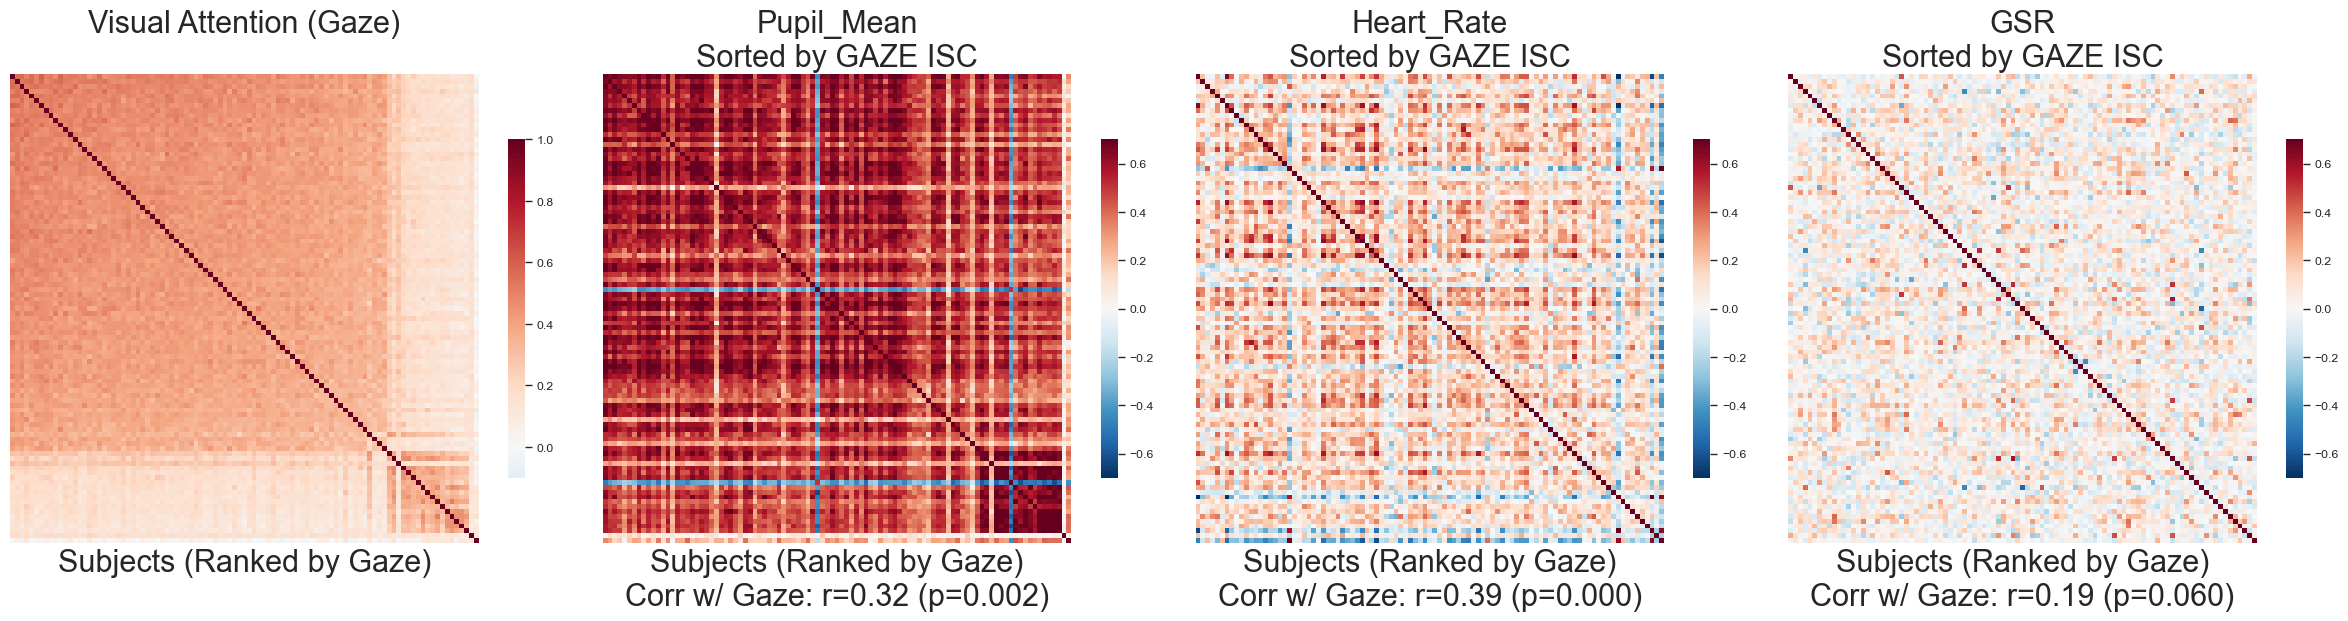

Analysis Complete.


In [55]:
#plt.rc('font', size=12) 


# ==========================================
# 3. HIERARCHY ANALYSIS: SORTED MATRICES
# ==========================================
print("\n--- Step 2: Running Matrix Reordering Analysis ---")

# A. DEFINE THE "DRIVER" (Visual Attention)
# We use the average of Gaze X and Y LOO scores as the "Attention Quality" index
print("Computing Gaze Consistency...")
loo_gaze_x = compute_loo_score(results['Gaze_X'])
loo_gaze_y = compute_loo_score(results['Gaze_Y'])
gaze_sync_scores = (loo_gaze_x + loo_gaze_y) / 2

# Calculate the Driver Matrix (Average of X and Y pairwise matrices)
mat_gaze_x = compute_pairwise_matrix(results['Gaze_X'])
mat_gaze_y = compute_pairwise_matrix(results['Gaze_Y'])
mat_gaze_combined = (mat_gaze_x + mat_gaze_y) / 2

# B. DETERMINE SORTING ORDER
# Sort from Highest Gaze Sync -> Lowest Gaze Sync
sort_indices = np.argsort(gaze_sync_scores)[::-1]

# Apply sorting to the Driver Matrix
sorted_gaze_mat = mat_gaze_combined[sort_indices][:, sort_indices]

# C. ANALYZE & PLOT "PASSENGER" SIGNALS
passenger_signals = ['Pupil_Mean', 'Heart_Rate', 'GSR'] 
# Note: Check if they exist in your 'results'
passenger_signals = [s for s in passenger_signals if s in results]

# Create Figure
fig, axes = plt.subplots(1, 1 + len(passenger_signals), figsize=(6 * (1+len(passenger_signals)), 6))
# If only one passenger, ensure axes is iterable
if len(passenger_signals) == 0: axes = [axes]
elif not isinstance(axes, np.ndarray): axes = [axes]

# --- Plot 1: GAZE (Reference) ---
sns.heatmap(sorted_gaze_mat, ax=axes[0], cmap='RdBu_r', center=0, vmin=-0.1, vmax=1.0, 
            square=True, cbar_kws={'shrink': 0.6})
axes[0].set_title("Visual Attention (Gaze)\n ", fontsize = 22)
axes[0].set_xlabel("Subjects (Ranked by Gaze)", fontsize = 22)
axes[0].set_yticks([])
axes[0].set_xticks([])

# --- Loop for Passengers ---
for i, signal in enumerate(passenger_signals):
    ax_idx = i + 1
    
    print(f"Processing {signal}...")
    
    # 1. Compute Scores & Matrix
    mat_physio = compute_pairwise_matrix(results[signal])
    loo_physio = compute_loo_score(results[signal])
    
    # 2. Sort Matrix using GAZE indices (Crucial Step!)
    sorted_physio_mat = mat_physio[sort_indices][:, sort_indices]
    
    # 3. Stats: Does Gaze predict this signal?
    r_val, p_val = pearsonr(gaze_sync_scores, loo_physio)
    
    # 4. Plot
    # Adjust vmax lower for physiology (usually 0.3-0.6)
    vmax_val = 0.7 #if signal == 'GSR' else 0.7 
    
    sns.heatmap(sorted_physio_mat, ax=axes[ax_idx], cmap='RdBu_r', center=0, vmin=-vmax_val, vmax=vmax_val, 
                square=True, cbar_kws={'shrink': 0.6})
    
    axes[ax_idx].set_title(f"{signal}\nSorted by GAZE ISC", fontsize = 22)
    axes[ax_idx].set_xlabel(f"Subjects (Ranked by Gaze)\nCorr w/ Gaze: r={r_val:.2f} (p={p_val:.3f})", fontsize = 22)
    axes[ax_idx].set_yticks([])
    axes[ax_idx].set_xticks([])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure_Hierarchy_SortedMatrices.png"), dpi=300)
plt.show()

print("Analysis Complete.")

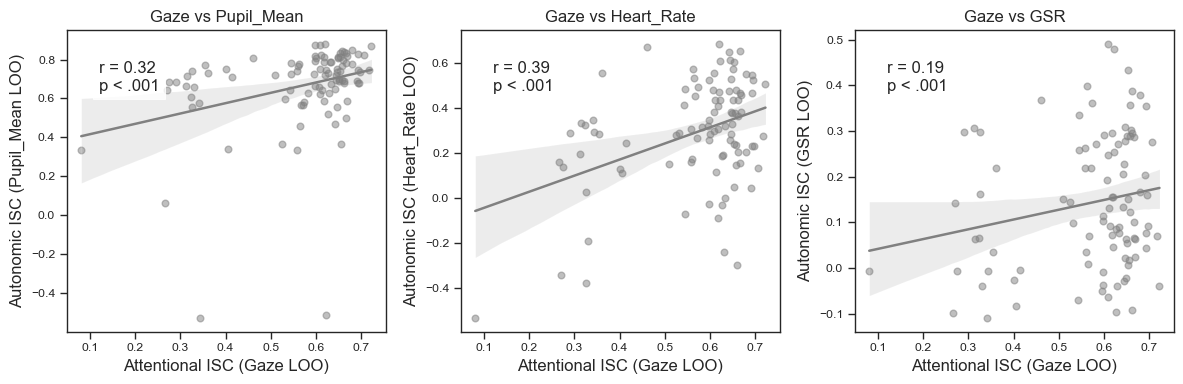

In [51]:
# 4. SCATTER PLOT VERIFICATION (Optional but great for the paper)
# This explicitly shows the correlation printed on the heatmaps
fig_scatter, ax_scatter = plt.subplots(1, 3, figsize=(12, 4))

for i, signal in enumerate(passenger_signals):
    if signal not in results:
        continue
        
    loo_physio = compute_loo_score(results[signal])
    
    sns.regplot(x=gaze_sync_scores, y=loo_physio, ax=ax_scatter[i], color='gray', scatter_kws={'alpha':0.5})
    ax_scatter[i].set_xlabel("Attentional ISC (Gaze LOO)",fontsize = 12)
    ax_scatter[i].set_ylabel(f"Autonomic ISC ({signal} LOO)",fontsize = 12)
    ax_scatter[i].set_title(f"Gaze vs {signal}",fontsize = 12)
    
    # Add stats annotation
    r, p = pearsonr(gaze_sync_scores, loo_physio)
    ax_scatter[i].text(0.1, 0.8, f"r = {r:.2f}\np < .001", transform=ax_scatter[i].transAxes, 
                       bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

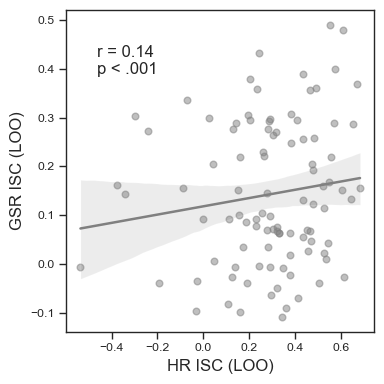

In [65]:
fig_scatter, ax_scatter = plt.subplots(1, 1, figsize=(4, 4))

loo_hr = compute_loo_score(results['Heart_Rate'])
loo_gsr = compute_loo_score(results['GSR'])


sns.regplot(x=loo_hr, y=loo_gsr, ax=ax_scatter, color='gray', scatter_kws={'alpha':0.5})
ax_scatter.set_xlabel("HR ISC (LOO)",fontsize = 12)
ax_scatter.set_ylabel("GSR ISC (LOO)",fontsize = 12)
    
# Add stats annotation
r, p = pearsonr(loo_hr, loo_gsr)
ax_scatter.text(0.1, 0.8, f"r = {r:.2f}\np < .001", transform=ax_scatter.transAxes, 
                       bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()